In [1]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
#import compute_observable_on_trjs_x01_v3

In [2]:
#-------------------------------- load trajectory -------------------------------

toppath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/input/seg_0035.gro"
trjpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/traj_comp.part0001-centered.xtc"
u = mda.Universe(toppath, trjpath)
protein_trj = u.select_atoms('protein')


In [3]:
#-------------------------------- select residues -------------------------------

whichprotein = "aac1"
threonine_location_info = [
    "on a helix facing the membrane core",
    "on a helix facing water or headgroups",
    "on a helix N terminal with no helix carbonyl to hydrogen bond with (variable solvation)",
    "on a loop (all of these are in water)"
]

#note that these are the residue numbers; which are one larger than the indices
threonines_ucp1 = [[193, 189, 121, 30, 122, 35],[226, 103, 97, 237, 259, 165, 166, 67, 62],[176, 177, 170, 156, 133, 60, 264],[11, 48, 108, 154]]
threonines_aac1 = [[23,125,161,196,218,232],[83,138,220],[253],[154,251]]

if whichprotein == "aac1":
    threonines_byloc = threonines_aac1
elif whichprotein == "ucp1":
    threonines_byloc = threonines_ucp1
else:
    print(f"invalid protein {whichprotein}")
    #return 0

threonine_inds_byloc = [[ii-1 for ii in i] for i in threonines_byloc]

#determine array dimensions necessary to encode residues in all location types in a single rectilinear numpy array
# this array is padded with values of 400 (outside the angle range returned by the dihedral calculation) 
# where there are not enough residues in a particular location type
n_frames = len(u.trajectory)
n_loctypes = len(threonines_byloc)
n_resis_per_loctype = max(len(lst) for lst in threonines_byloc)

In [ ]:
#-------------------------------- calculate dihedrals -------------------------------

#array to hold results for all threonines 
#of shape [number of location types, maximum number of residues at any one location type, number of frames]
angles_all = np.ones((n_loctypes, n_resis_per_loctype, n_frames))*400
print(angles_all.shape)

for loc_ind in range(n_loctypes):
    thr_inds = threonine_inds_byloc[loc_ind]
    #see https://userguide.mdanalysis.org/1.1.1/examples/analysis/structure/dihedrals.html
    chi1_atoms = [res.chi1_selection() for res in protein_trj.residues[thr_inds]]
    chi1_dihedrals = dihedrals.Dihedral(chi1_atoms).run()
    dihedral_angles = chi1_dihedrals.results.angles
    angles_all[loc_ind, 0:len(thr_inds)] = dihedral_angles.transpose()


(4, 6, 1311)


In [ ]:
#-------------------------------- digitize trajectory and calculate rotamer frequencies for each residue -------------------------------
#discretize trajectory

#mapping: 
#        a <= -120 : 0
# -120 < a <=    0 : 1
#    0 < a <=  120 : 2
#  120 < a <=  180 : 3
#  180 < a         : 4 #used to represent empty array entries (i.e. at location types with fewer residues)
angles_discrete = np.digitize(angles_all, [-120, 0, 120, 180], right=True) #this splits the rotamer centered on +-180 degrees into two bins
angles_discrete = np.where(angles_discrete == 3, 0, angles_discrete) #merge the bins for the rotamer at 180 degrees back together

#count occurrences of each rotamer
# note that due to trajectory length variability frequencies are not to be calculated until later
n_rotamers = 3
rotamer_counts = np.zeros((n_loctypes, n_resis_per_loctype, n_rotamers))

for rotamer_ind in range(n_rotamers):
    rotamers_onehot = np.where(angles_discrete == rotamer_ind, 1, 0)
    rotamer_counts[:,:,rotamer_ind] = np.sum(rotamers_onehot, axis = 2)
print(rotamer_counts)

[[[   0. 1311.    0.]
  [   0. 1299.   12.]
  [  84.  115. 1112.]
  [  44. 1225.   42.]
  [   2. 1188.  121.]
  [   0. 1311.    0.]]

 [[  15. 1130.  166.]
  [   0. 1311.    0.]
  [ 159.  737.  415.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]]

 [[   0.  287. 1024.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]]

 [[   0.   26. 1285.]
  [  43.  128. 1140.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]
  [   0.    0.    0.]]]


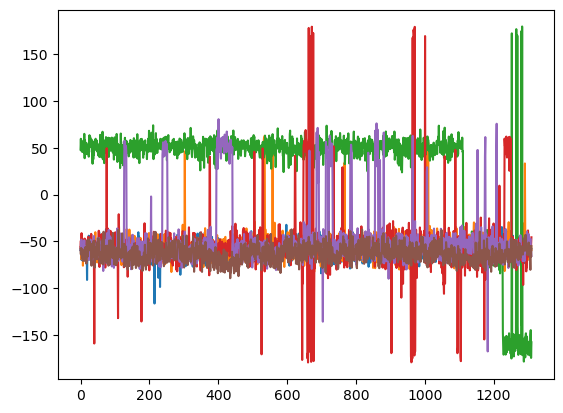

In [6]:
for i in dihedral_angles.transpose():
    plt.plot(i)

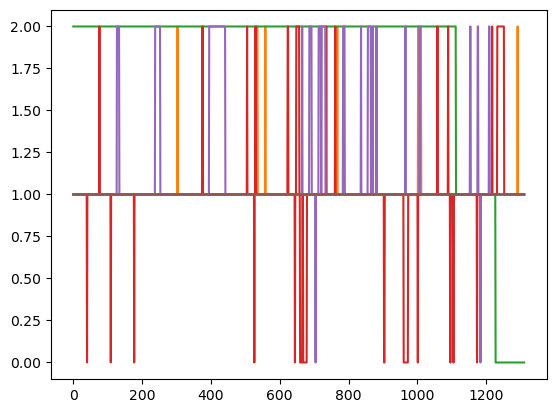

In [22]:
for i in angles_discrete[0]:
    plt.plot(i)

In [23]:
######################################################################################################
#                                               FIN
######################################################################################################

In [9]:
print(angles_all)

[[[400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]]

 [[400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]]

 [[400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]]

 [[400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]
  [400. 400. 400. ... 400. 400. 400.]]]


In [ ]:
threonines_byloc[loc_ind]

[23, 125, 161, 196, 218, 232]

In [ ]:
for res in whichprotein.residues:
    print(res)

<Residue SER, 1>
<Residue ASP, 2>
<Residue GLN, 3>
<Residue ALA, 4>
<Residue LEU, 5>
<Residue SER, 6>
<Residue PHE, 7>
<Residue LEU, 8>
<Residue LYS, 9>
<Residue ASP, 10>
<Residue PHE, 11>
<Residue LEU, 12>
<Residue ALA, 13>
<Residue GLY, 14>
<Residue GLY, 15>
<Residue VAL, 16>
<Residue ALA, 17>
<Residue ALA, 18>
<Residue ALA, 19>
<Residue ILE, 20>
<Residue SER, 21>
<Residue LYS, 22>
<Residue THR, 23>
<Residue ALA, 24>
<Residue VAL, 25>
<Residue ALA, 26>
<Residue PRO, 27>
<Residue ILE, 28>
<Residue GLU, 29>
<Residue ARG, 30>
<Residue VAL, 31>
<Residue LYS, 32>
<Residue LEU, 33>
<Residue LEU, 34>
<Residue LEU, 35>
<Residue GLN, 36>
<Residue VAL, 37>
<Residue GLN, 38>
<Residue HSD, 39>
<Residue ALA, 40>
<Residue SER, 41>
<Residue LYS, 42>
<Residue GLN, 43>
<Residue ILE, 44>
<Residue SER, 45>
<Residue ALA, 46>
<Residue GLU, 47>
<Residue LYS, 48>
<Residue GLN, 49>
<Residue TYR, 50>
<Residue LYS, 51>
<Residue GLY, 52>
<Residue ILE, 53>
<Residue ILE, 54>
<Residue ASP, 55>
<Residue CYS, 56>
<

In [ ]:
for res in whichprotein.residues[threonine_inds_byloc[loc_ind]]:
    print(res)

<Residue THR, 23>
<Residue THR, 125>
<Residue THR, 161>
<Residue THR, 196>
<Residue THR, 218>
<Residue THR, 232>
